In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random

data = pd.read_csv('../data/Task2/seeds_data.csv')

In [ ]:
data

In [ ]:
data.info()
data.describe()

In [2]:
data.Class.value_counts()

Class
1    70
2    70
3    70
Name: count, dtype: int64

In [11]:
def distance(a, b):
    return np.linalg.norm(a-b)

# K-Means

In [117]:
class KMeans:
    class Cluster:
        def __init__(self, model: KMeans):
            self.model = model
            self.indices = list[int]()
        def size(self):
            return len(self.indices)
        def add(self, idx: int):
            self.indices.append(idx)
        def retrieve(self):
            return self.model.data[self.indices,:]
        def reset(self):
            self.indices.clear()
        def mean(self):
            return self.retrieve().mean(axis=0)
        def wcss(self):
            mean = self.mean()
            data = self.retrieve()
            return sum(distance(x, mean)**2 for x in data)

    def __init__(self, data: pd.DataFrame, k=3):
        self.data = data.to_numpy()
        self.k = k

    def run(self) -> list[Cluster]:
        """ Implement the k-means clustering algorithm
        Returns: the resultant set of clusters
        """
        # random initial centroids
        centroids = self.data[random.sample(range(self.data.shape[0]), self.k)]
        clusters = [self.Cluster(self) for _ in range(self.k)]
        n = 1
        while True:
            old_centroids = centroids
            for c in clusters:
                c.reset()
            for idx in range(self.data.shape[0]):
                # compute distance from every cluster's centroid
                dists = list(map(lambda centroid: distance(self.data[idx], centroid), centroids))
                # add to the closest cluster
                clusters[np.argmin(dists)].add(idx)
            centroids = np.array([c.mean() for c in clusters])
            if np.all(old_centroids == centroids):
                break
            n += 1
        return clusters

    def cluster(self, N=5) -> list[Cluster]:
        """ Try clustering multiple times to get the set of clusters with the least WNCSS
        Args:
            N: number of attempts
        Returns: The best set of clusters
        """
        wcss = list()
        list_of_clusters = list()
        for i in range(N):
            clusters = model.run()
            wcss.append(sum([c.wcss() for c in clusters]))
            list_of_clusters.append(clusters)
        return list_of_clusters[np.argmin(wcss)]

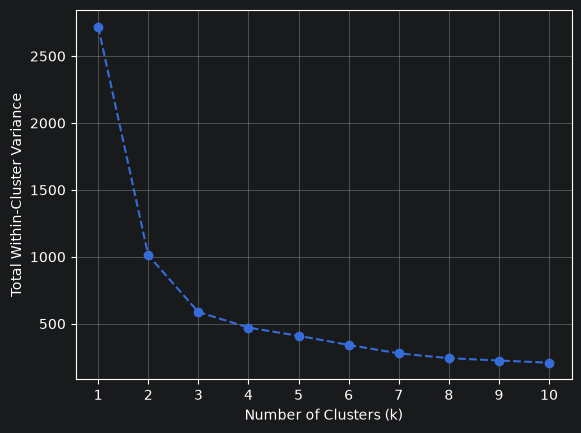

In [118]:
model = KMeans(data.drop(columns=['Class']))
y = list()
for k in range(1, 11):
    model.k = k
    var_sum = sum(c.wcss() for c in model.cluster())
    y.append(var_sum)
plt.plot(range(1, 11), y, marker='o', linestyle='--')
plt.xticks(range(1, 11))
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Total Within-Cluster Variance')
plt.grid()
plt.show()

In [120]:
model = KMeans(data.drop(columns=['Class']))
model.k = 3
clusters = model.cluster()

for c in clusters:
    print('Size:', c.size())
    print('Cluster labels:', data.Class[c.indices].to_list())
    print('Cluster center: ', c.mean())
    print()

Size: 72
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3]
Cluster center:  [14.64847222 14.46041667  0.87916667  5.56377778  3.27790278  2.64893333
  5.19231944]

Size: 61
Cluster labels: [1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Cluster center:  [18.72180328 16.29737705  0.88508689  6.20893443  3.72267213  3.60359016
  6.06609836]

Size: 77
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
Cluster center:  [11.96441558 13.27480519  0.8522      5.22928571  2.87292208  4.7

# DBSCAN

In [29]:
def standardize(data: pd.DataFrame):
    for col in data.columns:
        data[col] = (data[col] - data[col].mean()) / data[col].std()
    return data

In [122]:
class DBSCAN:
    class Point:
        def __init__(self, model: DBSCAN, idx: int):
            """ Construct a point
            Args:
                model: the parent DBSCAN model
                idx: the index of the point in the model data
            Other Attributes:
                neighbors: a list of neighboring points
                visited: whether the point has visited. Post run, falsity signifies noise.
            """
            self.model = model
            self.idx = idx
            self.neighbors = list[DBSCAN.Point]()
            self.visited = False

        def is_core(self):
            """ Check if the point is a core point
            Returns: True if neighbor count >= min_samples. False means it's a border point or noise.
            """
            return len(self.neighbors) >= self.model.min_samples

        def classify(self):
            """ Find neighboring points within eps """
            for pt in self.model.points:
                if distance(self.model.data[pt.idx], self.model.data[self.idx]) <= self.model.eps:
                    self.neighbors.append(pt)

        def visit(self):
            """ Mark the point as visited """
            self.visited = True

    class Cluster:
        def __init__(self, model: DBSCAN):
            """ Construct a cluster
            Args:
                model: the parent DBSCAN model
            Other Attributes:
                points: a list of constituent points
            """
            self.model = model
            self.points = list[DBSCAN.Point]()

        def size(self):
            """ Returns: the number of points in the cluster """
            return len(self.points)

        def add(self, pt: DBSCAN.Point):
            """ Add a point to the cluster """
            self.points.append(pt)

        def expand(self, root: DBSCAN.Point):
            """ Recursively expand the cluster 'til there are no more core points.
            Border points are added but not used for expansion. Noise is left unvisited.
            Args:
                root: the root point
            """
            for pt in root.neighbors:
                if not pt.visited:
                    pt.visit()
                    self.add(pt)
                    if pt.is_core():
                        self.expand(pt)

        def retrieve(self):
            """ Retrieve the cluster data
            Returns: a subdataset of the model data
            """
            return self.model.data[[pt.idx for pt in self.points],:]

    def __init__(self, data: pd.DataFrame, eps, min_samples):
        """ Construct a DBSCAN model and classify the points
        Args:
            data: the dataset
            eps: episilon, the radial limit of neighbors to a point
            min_samples: minimum neighboring points required for a point to be a core point
        Other Attributes:
            points: a list of the DBSCAN.Point form of the examples
        """
        self.data = data.to_numpy()
        self.eps = eps
        self.min_samples = min_samples
        self.points = [self.Point(self, idx) for idx in range(self.data.shape[0])]
        for pt in self.points:
            pt.classify()

    def run(self):
        """ Implement the DBSCAN clustering algorithm
        Returns: the resultant set of clusters and a dummy noise cluster
        """
        clusters = []
        for pt in self.points:
            if not pt.visited and pt.is_core():
                pt.visit()
                cluster = self.Cluster(self)
                cluster.add(pt)
                cluster.expand(pt)
                clusters.append(cluster)
        noise = self.Cluster(self)
        for pt in self.points:
            if not pt.visited:
                noise.add(pt)
        return clusters, noise


In [124]:
model = DBSCAN(standardize(data.drop(columns=['Class'])), .9, 10)
clusters, noise = model.run()

for c in clusters:
    print('Size:', c.size())
    print('Cluster labels:', data.Class[sorted([pt.idx for pt in c.points])].to_list())
    print()

print(f'{len(clusters)} clusters formed')
print(f'{noise.size()} noise points')

Size: 39
Cluster labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2]

Size: 60
Cluster labels: [1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

Size: 35
Cluster labels: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

3 clusters formed
76 noise points
